# Del pago digital al efectivo: ¿cómo se transmitió el shock a las ventas?

**Pregunta:** ¿cuánto de la caída de ventas se asocia a la falta de efectivo y al retroceso de los pagos digitales, y con qué rezago?

> **Aviso.** Los datos son **sintéticos**: un gemelo con mecanismo causal explícito y magnitudes ancladas a cifras públicas reportadas (≈ 80% de compras digitales antes del shock, ≈ 70% en efectivo después, caídas de ventas de hasta ≈ 70% en los días críticos y ≈ 30% a la semana siguiente). Los días posteriores al 15-nov-2026 son proyección sintética. Todo lo que aparece aquí es **asociación temporal**, no causalidad.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src import data_generator as dg, features as ft, ccf

plt.rcParams.update({"figure.figsize": (10, 3.6), "axes.grid": True, "grid.alpha": .25})
raw = dg.generate(seed=7)
f = ft.build_features(raw)
T0 = pd.Timestamp(dg.T0); OBS = pd.Timestamp(dg.OBS_END)
raw[["date","is_projection","digital_share_comercio","sales_comercio","cash_scarcity_idx"]].tail(3)

,date,is_projection,digital_share_comercio,sales_comercio,cash_scarcity_idx
362,2026-12-29,1,58.851983,78.539322,0.952261
363,2026-12-30,1,59.228130,86.099395,0.000000
364,2026-12-31,1,58.670949,88.103977,0.105311


## 1. Construir el contrafactual de ventas
Comparar ventas de noviembre con las de octubre confunde el efecto del shock con la estacionalidad (Black Friday, Navidad, aguinaldo).
Por eso se define una **brecha**: `ln(ventas / (nivel base × estacionalidad histórica))`, con el nivel base estimado solo con datos **previos al shock**.

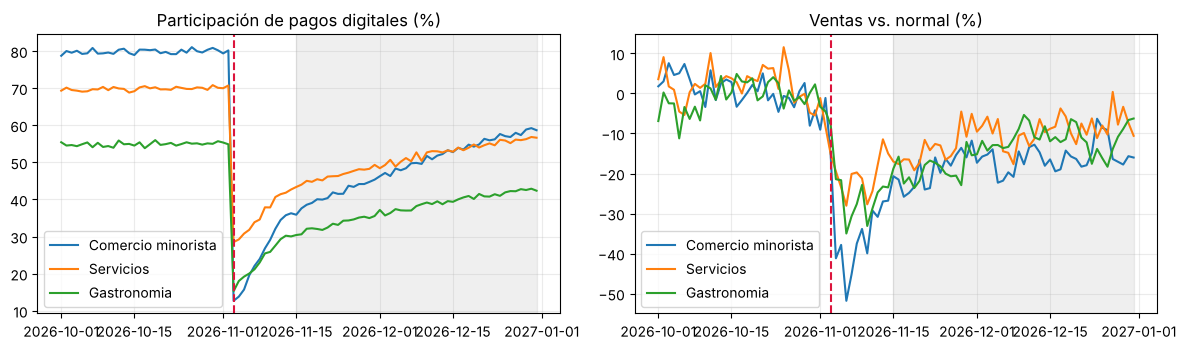

,Sector,Participacion digital pre (%),Participacion digital minima (%),Caida maxima de ventas (%),Caida promedio sem. 2 (%),Dias de ventas perdidos (a 15-nov),"Dias de ventas perdidos (a 31-dic, proy.)",Recuperacion a 95% del nivel
0,Comercio minorista,79.6,12.7,51.8,30.0,4.4,12.2,None
1,Servicios,69.6,28.5,28.0,19.4,2.6,7.4,2026-11-28
2,Gastronomia,54.7,15.3,35.0,25.1,3.2,9.6,None


In [2]:
g = f.set_index("date")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for s in dg.SECTORS:
    ax[0].plot(g.index[g.index >= "2026-10-01"], g.loc["2026-10-01":, f"digital_share_{s}"], label=dg.SECTORS[s]["label"])
    ax[1].plot(g.index[g.index >= "2026-10-01"], (np.exp(g.loc["2026-10-01":, f"sales_gap_{s}"]) - 1) * 100, label=dg.SECTORS[s]["label"])
for a, t in zip(ax, ["Participación de pagos digitales (%)", "Ventas vs. normal (%)"]):
    a.axvline(T0, color="crimson", ls="--"); a.axvspan(OBS, g.index[-1], color="grey", alpha=.12); a.set_title(t); a.legend()
plt.tight_layout(); plt.show()
ft.shock_kpis(f).round(1)

**Lectura.** El comercio minorista —el más digitalizado— cae más; servicios, menos. La zona gris es proyección sintética.

## 2. Correlación cruzada con rezagos
Convención: `k > 0` significa que el conductor **precede** a las ventas por `k` días. Para evitar correlaciones espurias entre series persistentes se usan **primeras diferencias** y **pre-blanqueo (Box-Jenkins)**; la banda es ±1,96/√n.

Primero, una verificación de la implementación con una serie de juguete cuyo rezago conocemos (3 días):

In [3]:
rng = np.random.default_rng(0)
x = rng.normal(size=400); y = np.roll(x, 3) + 0.3 * rng.normal(size=400)
r = ccf.ccf(x[10:], y[10:], 10)
print("Rezago recuperado:", int(r.idxmax()), "| r =", round(r.max(), 2))

Rezago recuperado: 3 | r = 0.96


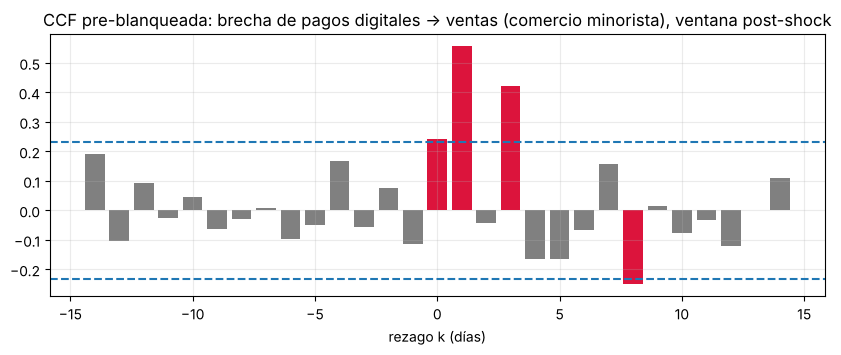

{'n': 72, 'peak_lag': 1, 'peak_r': 0.56, 'peak_significant': True}


In [4]:
y = g["sales_gap_comercio"]
x = ft.driver_series(f, "digital_gap", "comercio")
post = ccf.analyze(x, y, "2026-10-15", "2026-12-31", "prewhite")
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(post["ccf"].index, post["ccf"].values, color=["crimson" if abs(v) > post["band"] else "grey" for v in post["ccf"].values])
ax.axhline(post["band"], ls="--"); ax.axhline(-post["band"], ls="--")
ax.set_title("CCF pre-blanqueada: brecha de pagos digitales → ventas (comercio minorista), ventana post-shock")
ax.set_xlabel("rezago k (días)"); plt.show()
print({k: round(v, 2) if isinstance(v, float) else v for k, v in post.items() if k in ("peak_lag","peak_r","peak_significant","n")})

### Contraste pre-shock vs. post-shock
Si la relación es específica del evento, antes del shock la correlación debería ser mucho más débil.

In [5]:
pre = ccf.analyze(x, y, "2026-01-05", "2026-10-28", "prewhite")
print(f"Pre-shock : |r| máx = {abs(pre['peak_r']):.2f} (n={pre['n']})")
print(f"Post-shock: |r| máx = {abs(post['peak_r']):.2f} (n={post['n']})")

Pre-shock : |r| máx = 0.12 (n=291)
Post-shock: |r| máx = 0.56 (n=72)


## 3. Lo que la CCF **no** puede hacer: separar canales
Todos los conductores (pagos digitales, escasez de efectivo, retiros, dinero disponible, confianza) saltan **el mismo día**. Al medirlos contra las ventas, todos dan su máximo en el mismo rezago, aunque el generador siembra rezagos distintos por canal.

In [6]:
tab = ccf.summary_table(f, ft.DRIVERS, dg.SECTORS, "2026-10-15", "2026-12-31", "prewhite", ft.driver_series)
print("Rezagos sembrados en el generador:", dg.TRUE_LAGS)
tab[tab.sector_key == "comercio"][["Conductor", "Rezago del maximo (dias)", "r en el maximo", "Significativo (95%)"]].round(2)

Rezagos sembrados en el generador:

 {'digital': 1, 'scarcity': 3, 'trust': 7, 'money': 0}


,Conductor,Rezago del maximo (dias),r en el maximo,Significativo (95%)
0,Brecha de pagos digitales (pp),1,0.56,True
1,Escasez de efectivo (indice),1,-0.58,True
2,Retiros en cajeros (vs. normal),1,-0.51,True
3,Dinero disponible (vs. normal),1,0.56,True
4,Confianza en pagos digitales,1,0.56,True


In [7]:
d = pd.DataFrame({ft.DRIVERS[k]: ft.driver_series(f, k, "comercio") for k in ft.DRIVERS}).loc["2026-10-15":].corr().round(2)
d

,Brecha de pagos digitales (pp),Escasez de efectivo (indice),Retiros en cajeros (vs. normal),Dinero disponible (vs. normal),Confianza en pagos digitales
Brecha de pagos digitales (pp),1.00,-0.64,-0.98,0.63,0.99
Escasez de efectivo (indice),-0.64,1.00,0.74,-0.99,-0.55
Retiros en cajeros (vs. normal),-0.98,0.74,1.00,-0.72,-0.95
Dinero disponible (vs. normal),0.63,-0.99,-0.72,1.00,0.53
Confianza en pagos digitales,0.99,-0.55,-0.95,0.53,1.00


**Conclusión metodológica.** La CCF detecta bien el **momento** de transmisión (≈ 1 día después del shock) y confirma que la relación aparece solo con el evento. Pero con un único shock común y conductores casi colineales (|r| > 0,9) **no se puede atribuir el efecto a un canal**. Para hacerlo se necesita variación independiente: varios episodios, diferencias entre sectores o regiones, o microdatos. Reportar un "rezago por canal" con estos datos sería engañoso, y verificarlo contra la verdad sembrada es justamente la ventaja de trabajar con un gemelo sintético.

## 4. Velocidad de recuperación: liquidez vs. confianza
Un análisis descriptivo, libre de modelo, sí es informativo: ¿cuántos días tarda cada variable en recuperar la mitad de su desvío máximo?

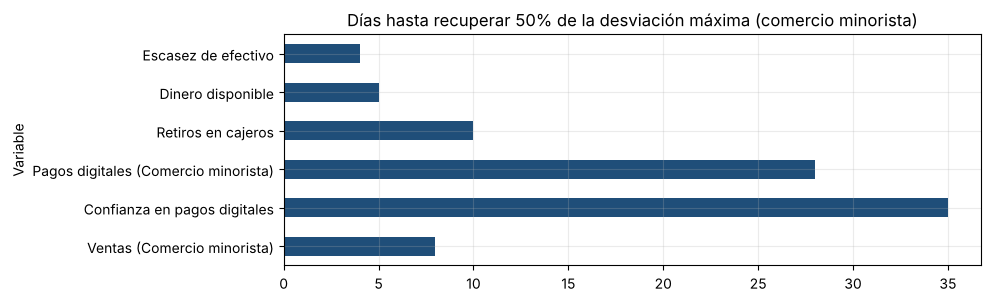

,Variable,Desviacion maxima,Dia del maximo,Dias a recuperar 50%,Dias a recuperar 90%
0,Escasez de efectivo,89.64,0,4,12.0
1,Dinero disponible,-0.27,0,5,9.0
2,Retiros en cajeros,0.72,0,10,NaN
3,Pagos digitales (Comercio minorista),-66.95,0,28,NaN
4,Confianza en pagos digitales,-0.42,0,35,NaN
5,Ventas (Comercio minorista),-0.73,3,8,51.0


In [8]:
rt = ft.recovery_table(f, "comercio")
ax = rt.set_index("Variable")["Dias a recuperar 50%"].plot.barh(figsize=(9, 3), color="#1f4e79"); ax.invert_yaxis()
ax.set_title("Días hasta recuperar 50% de la desviación máxima (comercio minorista)"); plt.show()
rt.round(2)

**Lectura (en este gemelo).** La liquidez (dinero disponible, escasez de efectivo) se normaliza en pocos días, mientras que los pagos digitales y la confianza tardan semanas. El daño persistente proviene de la **pérdida de confianza**, no de la falta de circulante. Esto es consecuencia del mecanismo sembrado; con datos reales (p. ej. transacciones de redes de pago, retiros en cajeros, ventas de comercios) habría que contrastarlo.

## 5. Escenario: ¿y si la confianza se restablece más rápido?

In [9]:
base = ft.shock_kpis(f).set_index("Sector")["Dias de ventas perdidos (a 31-dic, proy.)"]
fast = ft.shock_kpis(ft.build_features(dg.generate(seed=7, trust_halflife_days=20))).set_index("Sector")["Dias de ventas perdidos (a 31-dic, proy.)"]
pd.DataFrame({"Base (vida media 45 d)": base, "Confianza rápida (20 d)": fast, "Ahorro (%)": ((base - fast) / base * 100)}).round(1)

,Base (vida media 45 d),Confianza rápida (20 d),Ahorro (%)
Sector,,,
Comercio minorista,12.2,9.1,25.2
Servicios,7.4,5.6,24.9
Gastronomia,9.6,7.0,27.2


## 6. Qué se puede y qué no se puede concluir
- ✅ La relación temporal entre el retroceso de los pagos digitales y la caída de ventas **aparece con el evento** y se transmite en ≈ 1 día.
- ✅ La normalización de la liquidez es más rápida que la de los pagos digitales y las ventas.
- ❌ No se puede atribuir la caída a un canal específico con un solo shock.
- ❌ Las cifras son del gemelo sintético: ordenan la discusión, no sustituyen datos reales.

**Siguiente paso con datos reales:** reemplazar `data_generator.py` por la carga de series de transacciones, retiros y ventas, y añadir variación independiente (sectores, regiones, otros episodios) para identificar canales.